# 03 · Componente no supervisado: grupos y transacciones atípicas
**Regla del evento:** la variable `isFraud` **no entra** a ningún algoritmo. Se separa y se usa **solo al final** para interpretar si lo que encontramos tiene relación con el fraude.

**Orden del notebook:** Bloque A (preparar los datos) → Bloque B (agrupamiento) → Bloque C (transacciones atípicas) → Bloque D (visualización y conclusiones).

---
# Bloque A · Preparar los datos
Cargamos la misma muestra dividida por tiempo del notebook 01, separamos la etiqueta (que solo se usará al final para interpretar), preprocesamos y reducimos con PCA.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RAIZ = Path("..").resolve()            # raíz del repositorio
sys.path.append(str(RAIZ))
from src import preprocesamiento as pp

DATA_DIR = RAIZ / "data" / "raw"       # CSV originales
PROC_DIR = RAIZ / "data" / "processed" # muestra dividida (del notebook 01)
RES_DIR = RAIZ / "resultados"          # métricas en JSON
SEED = 42
N_MUESTRA = int(os.environ.get("N_MUESTRA", 150_000))

In [2]:
train = pp.agregar_features(pd.read_pickle(PROC_DIR / "train.pkl"))
test = pp.agregar_features(pd.read_pickle(PROC_DIR / "test.pkl"))
num, cat, informe = pp.seleccionar_columnas(train)   # decidido solo con el train
cols = num + cat
print(f"train: {train.shape} | test: {test.shape} | variables usadas: {len(cols)}")

train: (105000, 437) | test: (45000, 437) | variables usadas: 311


In [3]:
y_train, y_test = train[pp.TARGET].values, test[pp.TARGET].values   # SOLO para interpretar al final
pre = pp.preprocesador_lineal(num, cat)
Z_train = pre.fit_transform(train[cols])    # fit solo con train, sin etiqueta
Z_test = pre.transform(test[cols])

# Algunas variables anónimas llegan a 300 desviaciones estándar; sin recorte, esos pocos puntos dominan K-Means y PCA.
# Se recortan los valores estandarizados a ±5 (el 99,9 % de los valores ya está dentro de ±9).
Z_train, Z_test = np.clip(Z_train, -5, 5), np.clip(Z_test, -5, 5)

from sklearn.decomposition import PCA
acum = np.cumsum(PCA(random_state=SEED).fit(Z_train).explained_variance_ratio_)
N_PCA = int(np.searchsorted(acum, 0.90) + 1)
pca = PCA(n_components=N_PCA, random_state=SEED).fit(Z_train)
P_train, P_test = pca.transform(Z_train), pca.transform(Z_test)
print(f"{Z_train.shape[1]} columnas -> {N_PCA} componentes PCA (90 % de la varianza)")

398 columnas -> 86 componentes PCA (90 % de la varianza)


**Decisión sobre valores extremos.** Al estandarizar, algunas variables anónimas (`V305`, `V206`, `V241`…) tienen valores de hasta 324 desviaciones estándar. Probamos agrupar sin tocarlos y K-Means "separaba" un grupo diminuto de casos extremos (2.546 transacciones, y solo 18 con otros valores de *k*) y el resto quedaba en un solo bloque: el silhouette de 0,70 era un espejismo. Por eso recortamos los valores estandarizados a ±5 antes de PCA. Los grupos quedan más equilibrados y el Isolation Forest no empeora (de hecho mejora un poco), porque una transacción sigue viéndose extrema aunque se recorte.

---
# Bloque B · Agrupamiento (K-Means y mezcla gaussiana)
Primero justificamos los algoritmos, luego elegimos el número de grupos y comparamos los dos métodos.

## Justificación de los algoritmos
| Algoritmo | Qué busca | Por qué aquí | Supuestos | Limitaciones |
|---|---|---|---|---|
| **K-Means** | Grupos compactos alrededor de centros | Segmentar tipos de transacciones | Grupos esféricos y de tamaño parecido; hay que fijar *k* | Sensible a escala y atípicos |
| **Mezcla gaussiana (GMM)** | Grupos elípticos con probabilidad de pertenencia | Alternativa más flexible que K-Means | Cada grupo es una normal | Más costosa, sensible a la inicialización |
| **Isolation Forest** | Aislar puntos raros con árboles aleatorios | El fraude es raro: debería ser "diferente" | Las anomalías son pocas y distintas | Una transacción rara no es necesariamente fraude |

**En palabras sencillas:** K-Means reparte las transacciones en *k* grupos alrededor de centros; es rápido y fácil de leer, pero asume grupos redondos y parecidos en tamaño. La mezcla gaussiana es su versión más flexible: cada grupo puede ser alargado y cada transacción recibe una probabilidad de pertenecer a cada grupo. Isolation Forest hace otra cosa: no agrupa, sino que mide qué tan fácil es aislar una transacción con cortes al azar; las que quedan aisladas con pocos cortes son las más raras. Lo usamos porque el fraude es poco frecuente y podría verse "diferente" del resto. Ninguno de los tres usa la etiqueta `isFraud`.

### Elección de k
Probamos de 2 a 8 grupos y comparamos cuatro medidas: la inercia (qué tan juntos quedan los puntos de cada grupo), el *silhouette* (qué tan separados están los grupos; cuanto más alto, mejor), el índice de Davies-Bouldin (cuanto más bajo, mejor) y el de Calinski-Harabasz (cuanto más alto, mejor).

,inercia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,1.139210e+07,0.297,1.915,12676.146
3,1.073969e+07,0.103,2.867,9912.194
4,1.012796e+07,0.195,2.460,9121.096
5,9.679681e+06,0.094,2.504,8373.190
6,9.478053e+06,0.068,2.527,7287.697
7,9.094763e+06,0.073,2.280,7066.436
8,8.823035e+06,0.080,2.249,6705.356


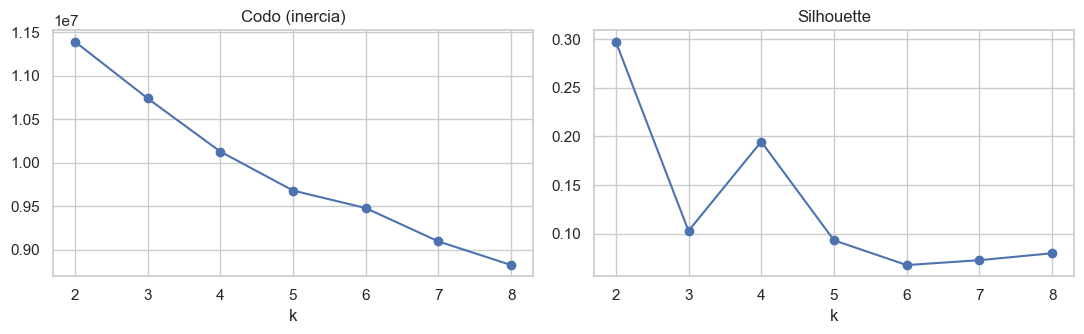

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(P_train)
    etq = km.labels_
    filas.append({"k": k, "inercia": km.inertia_,
                  "silhouette": silhouette_score(P_train, etq, sample_size=10_000, random_state=SEED),
                  "davies_bouldin": davies_bouldin_score(P_train, etq),
                  "calinski_harabasz": calinski_harabasz_score(P_train, etq)})
tabla_k = pd.DataFrame(filas).set_index("k")
display(tabla_k.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
tabla_k["inercia"].plot(marker="o", ax=ax[0], title="Codo (inercia)"); tabla_k["silhouette"].plot(marker="o", ax=ax[1], title="Silhouette")
plt.tight_layout(); plt.show()

**¿Cuántos grupos?** Las tres medidas apuntan a k = 2: tiene el mayor silhouette (0,30), el mayor índice de Calinski-Harabasz (12.677) y el menor Davies-Bouldin (1,92). La inercia baja de forma suave, sin un codo claro, y con más grupos el silhouette cae a 0,1 o menos. Elegimos k = 2, pero el silhouette de 0,30 es bajo: los datos no forman grupos bien separados, solo dos tipos de transacción.

In [5]:
K = int(tabla_k["silhouette"].idxmax())     # criterio: mayor silhouette (se puede fijar a mano y justificar)
print("k elegido:", K)
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(P_train)
lab_km_te = km.predict(P_test)

from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=K, covariance_type="diag", random_state=SEED).fit(P_train)
lab_gmm_te = gmm.predict(P_test)
comp = pd.DataFrame({
    "K-Means": [silhouette_score(P_test, lab_km_te, sample_size=10_000, random_state=SEED), davies_bouldin_score(P_test, lab_km_te), calinski_harabasz_score(P_test, lab_km_te)],
    "GMM": [silhouette_score(P_test, lab_gmm_te, sample_size=10_000, random_state=SEED), davies_bouldin_score(P_test, lab_gmm_te), calinski_harabasz_score(P_test, lab_gmm_te)]},
    index=["silhouette (↑)", "davies_bouldin (↓)", "calinski_harabasz (↑)"])
comp.round(3)

k elegido: 2


,K-Means,GMM
silhouette (↑),0.361,0.091
davies_bouldin (↓),1.972,4.625
calinski_harabasz (↑),5310.497,1661.659


### Interpretación de los grupos (aquí sí se usa la etiqueta, solo para entender)
¿Algún grupo concentra más fraude que el promedio? Si ninguno lo hace, también es un resultado: los grupos describen *tipos de transacción*, no *fraude*.

In [6]:
def perfil(etiquetas, nombre):
    t = pd.DataFrame({"grupo": etiquetas, "fraude": y_test}).groupby("grupo")["fraude"].agg(["count", "mean"])
    t["tasa_fraude_%"] = t["mean"] * 100; t["lift"] = t["mean"] / y_test.mean()
    print(f"--- {nombre}: tasa de fraude global = {y_test.mean():.2%}")
    return t[["count", "tasa_fraude_%", "lift"]].round(2)
display(perfil(lab_km_te, "K-Means"))
display(perfil(lab_gmm_te, "GMM"))

resumen = test.assign(grupo=lab_km_te).groupby("grupo").agg(monto_medio=("TransactionAmt", "mean"), hora_media=("hora", "mean"))
display(resumen.round(1))
display(pd.crosstab(test["ProductCD"], lab_km_te, normalize="columns").round(2))

--- K-Means: tasa de fraude global = 3.60%


,count,tasa_fraude_%,lift
grupo,,,
0,4851,13.17,3.65
1,40149,2.45,0.68


--- GMM: tasa de fraude global = 3.60%


,count,tasa_fraude_%,lift
grupo,,,
0,22789,1.23,0.34
1,22211,6.04,1.68


,monto_medio,hora_media
grupo,,
0,49.9,12.3
1,146.4,14.2


col_0,0,1
ProductCD,,
C,0.87,0.01
H,0.01,0.03
R,0.03,0.05
S,0.09,0.02
W,0.00,0.90


---
# Bloque C · Transacciones atípicas (Isolation Forest)

## Isolation Forest
No se le dice cuánto fraude hay (`contamination="auto"`); se ordenan las transacciones por qué tan raras son y se mide, después, si las más raras coinciden con el fraude.

In [7]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score
iso = IsolationForest(n_estimators=200, contamination="auto", random_state=SEED, n_jobs=-1).fit(P_train)
puntaje = -iso.score_samples(P_test)       # más alto = más raro
res_iso = {"roc_auc": roc_auc_score(y_test, puntaje), "pr_auc": average_precision_score(y_test, puntaje), "prevalencia": float(y_test.mean())}
print({k: round(v, 3) for k, v in res_iso.items()})

filas = []
for pct in [1, 3, 5, 10]:
    corte = np.percentile(puntaje, 100 - pct); marcadas = puntaje >= corte
    filas.append({"% marcado como raro": pct, "precision": y_test[marcadas].mean(), "recall": y_test[marcadas].sum() / y_test.sum(),
                  "lift": y_test[marcadas].mean() / y_test.mean()})
display(pd.DataFrame(filas).round(3))

{'roc_auc': 0.752, 'pr_auc': 0.119, 'prevalencia': 0.036}


,% marcado como raro,precision,recall,lift
0,1,0.056,0.015,1.541
1,3,0.212,0.176,5.878
2,5,0.196,0.271,5.425
3,10,0.150,0.415,4.149


---
# Bloque D · Visualización, resultados guardados y conclusiones

## PCA frente a t-SNE
PCA es lineal y conserva la varianza global; t-SNE conserva vecindades locales y revela grupos, pero distorsiona distancias y no se interpreta en sus ejes.

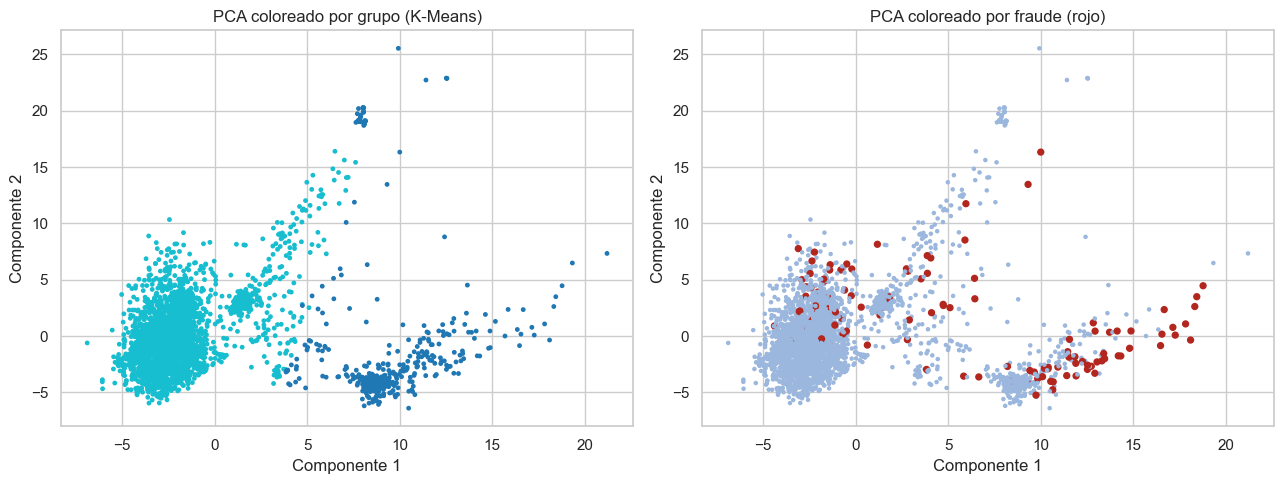

Las 2 primeras componentes conservan 19.1% de la varianza: el resto se pierde en este gráfico.


In [8]:
rng = np.random.RandomState(SEED)
idx = rng.choice(len(P_test), size=min(4000, len(P_test)), replace=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(P_test[idx, 0], P_test[idx, 1], c=lab_km_te[idx], cmap="tab10", s=6); ax[0].set_title("PCA coloreado por grupo (K-Means)")
col = np.where(y_test[idx] == 1, "#B3261E", "#9BB7DD")
ax[1].scatter(P_test[idx, 0], P_test[idx, 1], c=col, s=np.where(y_test[idx] == 1, 18, 5)); ax[1].set_title("PCA coloreado por fraude (rojo)")
for a in ax: a.set_xlabel("Componente 1"); a.set_ylabel("Componente 2")
plt.tight_layout(); plt.show()
print(f"Las 2 primeras componentes conservan {pca.explained_variance_ratio_[:2].sum():.1%} de la varianza: el resto se pierde en este gráfico.")

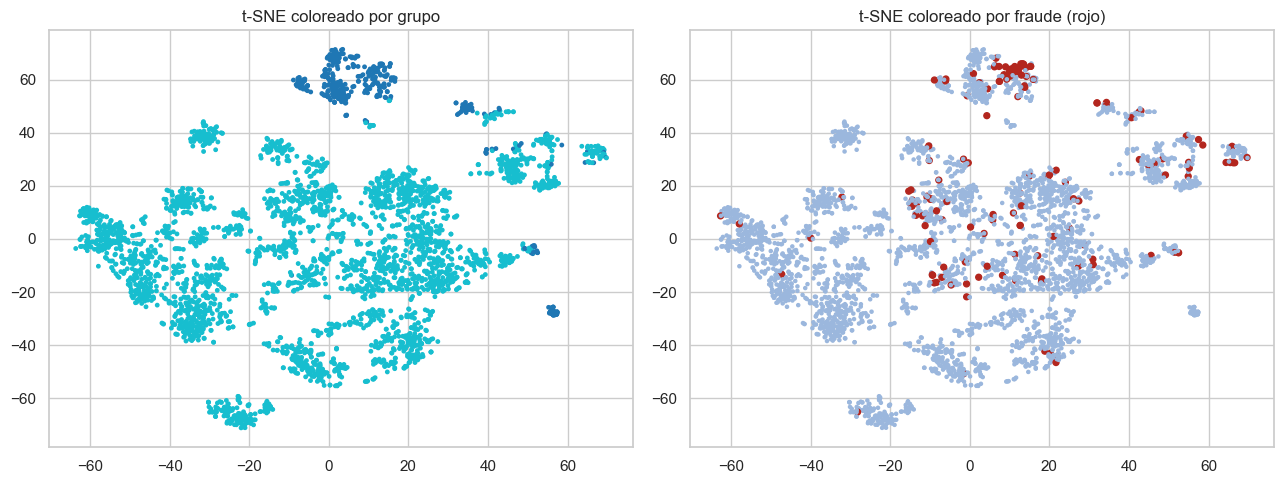

In [9]:
from sklearn.manifold import TSNE
emb = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(P_test[idx][:, :min(30, N_PCA)])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(emb[:, 0], emb[:, 1], c=lab_km_te[idx], cmap="tab10", s=6); ax[0].set_title("t-SNE coloreado por grupo")
ax[1].scatter(emb[:, 0], emb[:, 1], c=col, s=np.where(y_test[idx] == 1, 18, 5)); ax[1].set_title("t-SNE coloreado por fraude (rojo)")
plt.tight_layout(); plt.show()

In [10]:
RES_DIR.mkdir(exist_ok=True)
sil = tabla_k["silhouette"]
salida = {"pca_componentes": N_PCA, "k_elegido": K,
          "comparacion_agrupamiento": comp.round(4).to_dict(),
          "kmeans_tasa_fraude_por_grupo": perfil(lab_km_te, "K-Means")["tasa_fraude_%"].to_dict(),
          "isolation_forest": {k: float(v) for k, v in res_iso.items()},
          "isolation_forest_top": pd.DataFrame(filas).round(4).to_dict(orient="records")}
(RES_DIR / "no_supervisado.json").write_text(json.dumps(salida, indent=2, default=float, ensure_ascii=False), encoding="utf-8")
print("guardado en resultados/no_supervisado.json")

--- K-Means: tasa de fraude global = 3.60%
guardado en resultados/no_supervisado.json


## Conclusiones del componente no supervisado
- **Qué estructura apareció:** los datos se separan sobre todo en dos tipos de transacción. Un grupo pequeño (cerca del 11 % de la prueba) está compuesto casi todo por el producto C (87 %), con montos bajos (promedio de unos 50); el grupo grande (89 %) es casi todo producto W (90 %), con montos más altos (promedio de unos 146). Es una estructura real, pero describe *tipos de transacción*, no fraude directamente.
- **¿Algún grupo concentra fraude?** Sí, en parte: el grupo pequeño del producto C tiene 13,2 % de fraude, unas 3,7 veces el promedio (3,6 %), mientras que el grande tiene 2,5 %. Coincide con lo que vimos en el análisis exploratorio, donde el producto C tenía mucho más fraude que el W. La mezcla gaussiana separó dos grupos con 1,2 % y 6,0 % de fraude, pero con grupos de tamaños parecidos y menos nítidos.
- **Qué tan bien separan los grupos:** poco. El mejor silhouette fue 0,30 para k = 2 y baja a valores cercanos a 0,1 con más grupos; en la prueba, K-Means llegó a 0,36 y la mezcla gaussiana solo a 0,09, con un Davies-Bouldin mucho peor. La estructura de grupos de estos datos es débil, y K-Means resultó mejor que la mezcla gaussiana.
- **Isolation Forest, sin usar la etiqueta:** ordena las transacciones por rareza y logra ROC-AUC de 0,75 y PR-AUC de 0,12, unas 3 veces el azar (0,036). Si se marca como rara el 3 % de las transacciones, 21 % de ellas son fraude (unas 6 veces el promedio) y se captura el 18 % de los fraudes. Es mucho menos que el supervisado (PR-AUC 0,48), pero sin haber visto jamás una etiqueta: una transacción rara tiene más probabilidad de ser fraude, aunque no todo lo raro lo es.
- **Valores extremos:** unas pocas variables anónimas llegan a más de 300 desviaciones estándar. Sin recortarlas, K-Means formaba un grupo diminuto de casos extremos y el silhouette de 0,70 era engañoso; por eso se recortaron a ±5.
- **Qué se pierde al reducir dimensiones:** para conservar el 90 % de la varianza hacen falta 86 componentes (de 398 columnas). Las dos primeras componentes, que son las que se dibujan, conservan solo el 19 % de la varianza, así que los gráficos en 2D muestran únicamente una parte de la estructura. t-SNE ayuda a ver vecindades locales, pero distorsiona las distancias y sus ejes no se interpretan.